# MACHINE LEARNING
## Prediksi Repeat Customer pada Dataset E-Commerce

**Nama:** RAIHAN DWI PRAMANA 05TPLP018  
**Mata Kuliah:** Machine Learning

### Dataset
fast_food_cheat_meal_workout_burn.csv

### Deskripsi
Proyek ini bertujuan membangun model Machine Learning untuk
memprediksi kategori `workout_shock_tier` berdasarkan informasi
makanan cepat saji dan karakteristik konsumen.

### Jenis Machine Learning
Random Forest Classification.


## 1. Import Library

Pada tahap ini, kita mengimpor library yang diperlukan untuk
membaca dataset, melakukan eksplorasi data, membuat visualisasi,
dan membangun model Random Forest.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Mengatur tampilan grafik
sns.set_theme(style="whitegrid")

# Menampilkan angka desimal dengan 2 digit
pd.set_option("display.float_format", "{:.2f}".format)



## 2. Membaca Dataset

Dataset dibaca menggunakan Pandas. File CSV harus berada
di folder yang sama dengan notebook agar mudah ditemukan.
Setelah dibaca, kita menampilkan beberapa baris pertama
untuk mengenali struktur data.

In [2]:

# Membaca file dataset CSV
df = pd.read_csv("dataset/fast_food_cheat_meal_workout_burn.csv")

# Menampilkan lima baris pertama
display(df.head())

,order_id,fast_food_chain,meal_category,item_count,total_calories,fat_grams,saturated_fat_grams,carb_grams,sugar_grams,protein_grams,...,consumer_weight_kg,fitness_level,thermic_effect_calories,net_caloric_surplus,walking_burn_time_min,cycling_burn_time_min,running_burn_time_min,hiit_burn_time_min,daily_calorie_allowance_pct,workout_shock_tier
0,FFC-00001,McDonald's,Late-Night Value Menu Binge,3,1015,47,19,117,55,32,...,96.00,Moderately Active,77.90,937.10,168.30,80.80,60.20,46.50,50.70,High Sweat Penalty
1,FFC-00002,Taco Bell,Fried Chicken Bucket & Slaw,5,1849,103,32,166,61,65,...,53.60,Moderately Active,136.70,1712.30,550.70,261.70,185.50,161.10,92.40,Extreme / Half-Marathon Toll
2,FFC-00003,Domino's Pizza,Pizza Feast & Cheesy Bread,2,1920,106,50,184,61,57,...,67.00,Moderately Active,135.00,1785.00,463.90,219.50,157.80,131.10,96.00,Extreme / Half-Marathon Toll
3,FFC-00004,McDonald's,Dessert Overload & Large Shake,2,1255,67,25,135,42,27,...,62.60,Sedentary,82.30,1172.70,351.00,166.50,120.30,103.40,62.70,Extreme / Half-Marathon Toll
4,FFC-00005,Taco Bell,Double Burger & Large Fry,4,1665,88,32,155,69,62,...,73.00,Moderately Active,127.40,1537.60,361.30,170.90,119.10,104.90,83.20,Severe Cardio Deficit



## 3. Memahami Struktur Dataset

Tahap ini digunakan untuk mengetahui jumlah baris dan kolom,
nama kolom, tipe data, serta gambaran awal isi dataset.
Informasi tersebut membantu menentukan langkah pengolahan
data yang diperlukan.

In [3]:

# Menampilkan jumlah baris dan kolom
print("Jumlah baris dan kolom:", df.shape)

# Menampilkan nama semua kolom
print("\nDaftar kolom:")
print(df.columns.tolist())

# Menampilkan tipe data dan jumlah data non-kosong
print("\nInformasi dataset:")
df.info()

# Menampilkan statistik deskriptif
print("\nStatistik deskriptif:")
display(df.describe(include="all").T)

Jumlah baris dan kolom: (8000, 23)

Daftar kolom:
['order_id', 'fast_food_chain', 'meal_category', 'item_count', 'total_calories', 'fat_grams', 'saturated_fat_grams', 'carb_grams', 'sugar_grams', 'protein_grams', 'sodium_mg', 'consumer_gender', 'consumer_age', 'consumer_weight_kg', 'fitness_level', 'thermic_effect_calories', 'net_caloric_surplus', 'walking_burn_time_min', 'cycling_burn_time_min', 'running_burn_time_min', 'hiit_burn_time_min', 'daily_calorie_allowance_pct', 'workout_shock_tier']

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 23 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   order_id                     8000 non-null   str    
 1   fast_food_chain              8000 non-null   str    
 2   meal_category                8000 non-null   str    
 3   item_count                   8000 non-null   int64  
 4   total_calories               80

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,8000,8000,FFC-00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fast_food_chain,8000,9,McDonald's,1748,NaN,NaN,NaN,NaN,NaN,NaN,NaN
meal_category,8000,6,"Loaded Burrito, Nachos & Soda",1399,NaN,NaN,NaN,NaN,NaN,NaN,NaN
item_count,8000.00,NaN,NaN,NaN,3.50,1.12,2.00,2.00,4.00,5.00,5.00
total_calories,8000.00,NaN,NaN,NaN,1602.57,672.13,750.00,1080.00,1479.00,2008.00,3600.00
fat_grams,8000.00,NaN,NaN,NaN,80.06,34.29,32.00,53.00,74.00,100.00,190.00
saturated_fat_grams,8000.00,NaN,NaN,NaN,31.99,14.40,10.00,21.00,29.00,40.00,75.00
carb_grams,8000.00,NaN,NaN,NaN,165.96,70.79,66.00,110.00,153.00,208.00,380.00
sugar_grams,8000.00,NaN,NaN,NaN,62.25,31.80,14.00,39.00,55.00,79.00,175.00
protein_grams,8000.00,NaN,NaN,NaN,54.04,30.69,15.00,30.00,48.00,71.00,140.00



## 4. Pemeriksaan Kualitas Data

Pemeriksaan dilakukan untuk mengetahui apakah terdapat
nilai kosong dan baris duplikat. Data yang bermasalah perlu
ditangani agar proses pelatihan model berjalan dengan baik.

In [4]:

# Menghitung nilai kosong setiap kolom
print("Nilai kosong per kolom:")
display(df.isnull().sum())

# Menghitung jumlah seluruh nilai kosong
print("Total nilai kosong:", df.isnull().sum().sum())

# Menghitung jumlah baris duplikat
print("Jumlah baris duplikat:", df.duplicated().sum())

Nilai kosong per kolom:


order_id                       0
fast_food_chain                0
meal_category                  0
item_count                     0
total_calories                 0
fat_grams                      0
saturated_fat_grams            0
carb_grams                     0
sugar_grams                    0
protein_grams                  0
sodium_mg                      0
consumer_gender                0
consumer_age                   0
consumer_weight_kg             0
fitness_level                  0
thermic_effect_calories        0
net_caloric_surplus            0
walking_burn_time_min          0
cycling_burn_time_min          0
running_burn_time_min          0
hiit_burn_time_min             0
daily_calorie_allowance_pct    0
workout_shock_tier             0
dtype: int64

Total nilai kosong: 0
Jumlah baris duplikat: 0



## 5. Analisis Distribusi Target

Kolom `workout_shock_tier` merupakan variabel target yang
akan diprediksi. Grafik batang digunakan untuk mengetahui
jumlah data pada setiap kategori target dan melihat apakah
distribusi kelas relatif seimbang.

workout_shock_tier
Extreme / Half-Marathon Toll    3257
Severe Cardio Deficit           2429
High Sweat Penalty              2122
Moderate Burn                    192
Name: count, dtype: int64


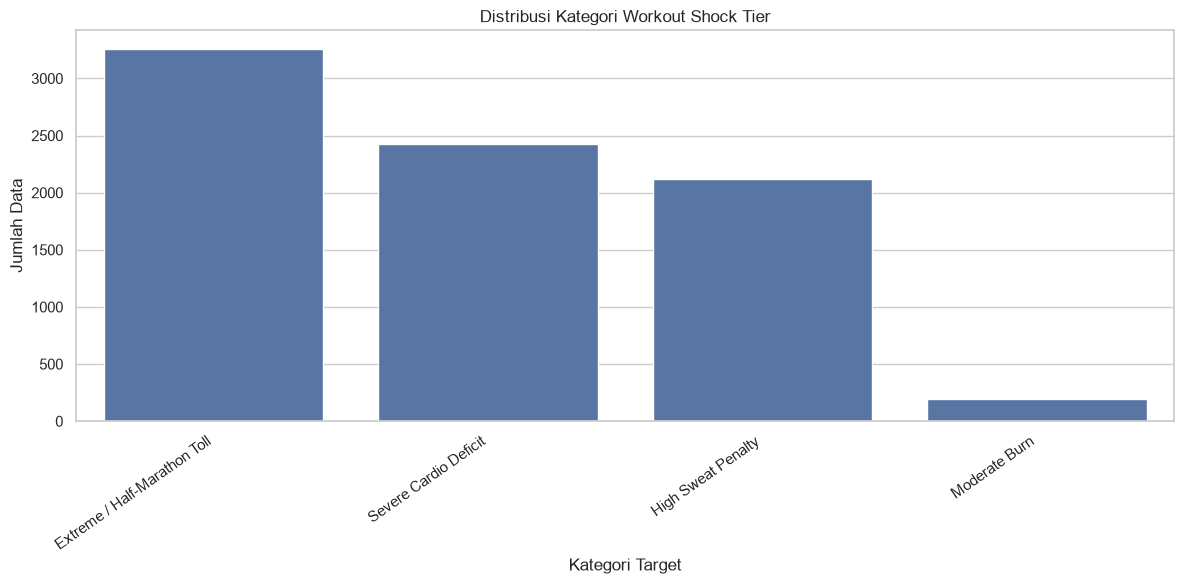

In [5]:

# Menghitung jumlah data setiap kategori target
target_counts = df["workout_shock_tier"].value_counts()

# Menampilkan jumlah data
print(target_counts)

# Membuat grafik distribusi kategori target
plt.figure(figsize=(12, 6))
sns.countplot(
    data=df,
    x="workout_shock_tier",
    order=target_counts.index
)

plt.title("Distribusi Kategori Workout Shock Tier")
plt.xlabel("Kategori Target")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


## 6. Menentukan Fitur dan Target

Target penelitian adalah `workout_shock_tier`.
Fitur yang digunakan meliputi jumlah kalori, kandungan gizi,
kategori restoran dan makanan, serta karakteristik konsumen.

Kolom ID transaksi tidak digunakan sebagai fitur. Kolom
hasil perhitungan lanjutan seperti waktu olahraga, surplus
kalori, dan persentase kebutuhan kalori juga dikeluarkan
untuk mengurangi risiko data leakage, yaitu ketika model
menggunakan informasi yang terlalu dekat dengan pembentukan
target.

In [6]:

# Menentukan kolom target
target = "workout_shock_tier"

# Kolom yang tidak digunakan sebagai fitur
kolom_dihapus = [
    "order_id",
    "thermic_effect_calories",
    "net_caloric_surplus",
    "walking_burn_time_min",
    "cycling_burn_time_min",
    "running_burn_time_min",
    "hiit_burn_time_min",
    "daily_calorie_allowance_pct"
]

# Memastikan kolom target tersedia
if target not in df.columns:
    raise ValueError(f"Kolom target '{target}' tidak ditemukan.")

# Memisahkan fitur dan target
X = df.drop(columns=[target] + kolom_dihapus, errors="ignore")
y = df[target]

# Menampilkan fitur yang digunakan
print("Jumlah fitur:", X.shape[1])
print("\nNama fitur:")
print(X.columns.tolist())

print("\nDistribusi target:")
print(y.value_counts())

Jumlah fitur: 14

Nama fitur:
['fast_food_chain', 'meal_category', 'item_count', 'total_calories', 'fat_grams', 'saturated_fat_grams', 'carb_grams', 'sugar_grams', 'protein_grams', 'sodium_mg', 'consumer_gender', 'consumer_age', 'consumer_weight_kg', 'fitness_level']

Distribusi target:
workout_shock_tier
Extreme / Half-Marathon Toll    3257
Severe Cardio Deficit           2429
High Sweat Penalty              2122
Moderate Burn                    192
Name: count, dtype: int64



## 7. Pembagian Data Training dan Testing

Dataset dibagi menjadi 80% data training dan 20% data testing.
Data training digunakan untuk melatih model, sedangkan data
testing digunakan untuk mengevaluasi kemampuan model terhadap
data yang tidak digunakan selama pelatihan.

Parameter stratify digunakan untuk menjaga proporsi kategori
target pada kedua bagian data.

In [7]:

# Membagi dataset menjadi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Menampilkan jumlah data
print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

print("\nDistribusi target data training:")
print(y_train.value_counts())

print("\nDistribusi target data testing:")
print(y_test.value_counts())

Jumlah data training: 6400
Jumlah data testing: 1600

Distribusi target data training:
workout_shock_tier
Extreme / Half-Marathon Toll    2605
Severe Cardio Deficit           1943
High Sweat Penalty              1698
Moderate Burn                    154
Name: count, dtype: int64

Distribusi target data testing:
workout_shock_tier
Extreme / Half-Marathon Toll    652
Severe Cardio Deficit           486
High Sweat Penalty              424
Moderate Burn                    38
Name: count, dtype: int64



## 8. Preprocessing Data

Random Forest memerlukan data kategorikal dalam bentuk
numerik. Oleh karena itu, kolom kategorikal diubah dengan
One-Hot Encoding. Nilai kosong ditangani menggunakan imputasi:
median untuk fitur numerik dan modus untuk fitur kategorikal.

Proses preprocessing dibangun menggunakan Pipeline agar
langkah pengolahan dipelajari dari data training saja,
sehingga mengurangi risiko kebocoran informasi dari data testing.

In [8]:

# Mengidentifikasi kolom numerik dan kategorikal
kolom_numerik = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

kolom_kategorikal = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Kolom numerik:", kolom_numerik)
print("\nKolom kategorikal:", kolom_kategorikal)

# Pipeline untuk fitur numerik
proses_numerik = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Pipeline untuk fitur kategorikal
proses_kategorikal = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Menggabungkan preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("numerik", proses_numerik, kolom_numerik),
        ("kategorikal", proses_kategorikal, kolom_kategorikal)
    ]
)

print("\nPreprocessing berhasil disiapkan.")

Kolom numerik: ['item_count', 'total_calories', 'fat_grams', 'saturated_fat_grams', 'carb_grams', 'sugar_grams', 'protein_grams', 'sodium_mg', 'consumer_age', 'consumer_weight_kg']

Kolom kategorikal: ['fast_food_chain', 'meal_category', 'consumer_gender', 'fitness_level']

Preprocessing berhasil disiapkan.



## 9. Pembuatan Model Random Forest Classification

Random Forest merupakan algoritma klasifikasi yang
menggabungkan prediksi dari banyak pohon keputusan.
Model digunakan untuk mempelajari pola antara fitur makanan
dan konsumen dengan kategori target `workout_shock_tier`.

Model disusun dalam Pipeline bersama preprocessing agar
proses transformasi dan pelatihan dilakukan secara konsisten.

In [9]:

# Membuat pipeline model Random Forest
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Melatih model menggunakan data training
model.fit(X_train, y_train)

print("Model Random Forest berhasil dilatih.")

Model Random Forest berhasil dilatih.



## 10. Evaluasi Model

Model diuji menggunakan data testing. Evaluasi dilakukan
menggunakan accuracy, precision, recall, dan F1-score.

Accuracy menunjukkan proporsi prediksi yang benar.
Precision mengukur ketepatan prediksi suatu kelas, recall
mengukur kemampuan menemukan data dari kelas tersebut,
sedangkan F1-score merupakan gabungan precision dan recall.

In [10]:

# Memprediksi kategori pada data testing
y_pred = model.predict(X_test)

# Menghitung akurasi
akurasi = accuracy_score(y_test, y_pred)
print(f"Akurasi model: {akurasi:.4f}")
print(f"Akurasi model: {akurasi * 100:.2f}%")

# Menampilkan laporan evaluasi setiap kelas
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Akurasi model: 0.8906
Akurasi model: 89.06%

Classification Report:
                              precision    recall  f1-score   support

Extreme / Half-Marathon Toll       0.93      0.92      0.93       652
          High Sweat Penalty       0.90      0.90      0.90       424
               Moderate Burn       0.80      0.63      0.71        38
       Severe Cardio Deficit       0.83      0.85      0.84       486

                    accuracy                           0.89      1600
                   macro avg       0.87      0.83      0.84      1600
                weighted avg       0.89      0.89      0.89      1600




## 11. Confusion Matrix

Confusion matrix digunakan untuk membandingkan kategori
sebenarnya dengan kategori hasil prediksi model.

Nilai pada diagonal menunjukkan prediksi yang benar,
sedangkan nilai di luar diagonal menunjukkan kesalahan
klasifikasi antar kategori.

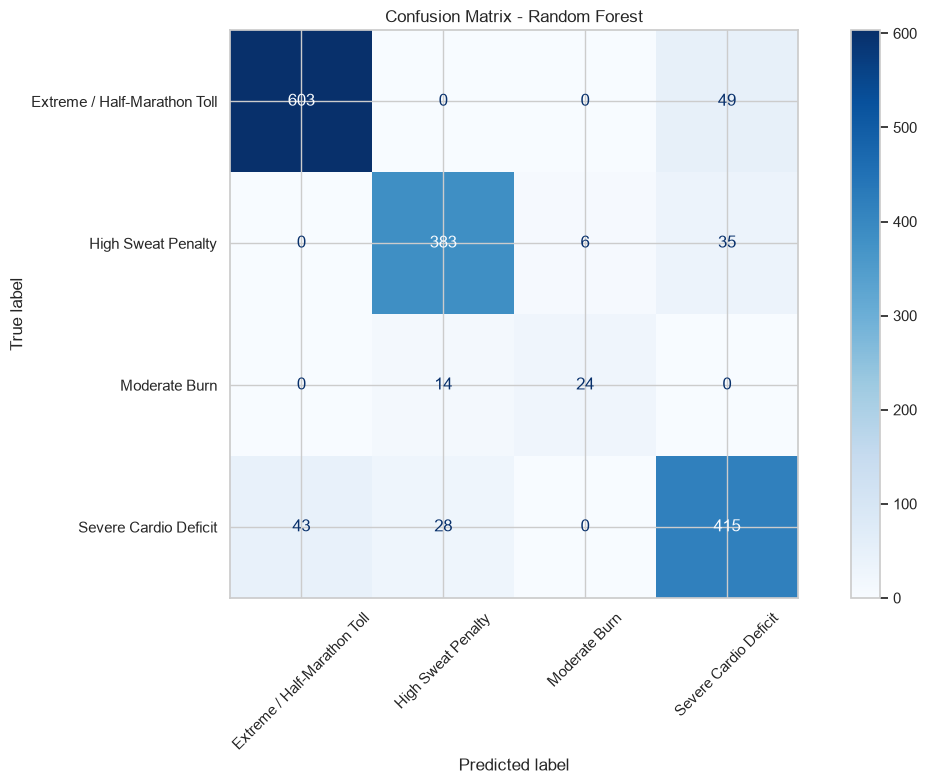

In [11]:

# Membuat confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

# Menampilkan confusion matrix sebagai grafik
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

fig, ax = plt.subplots(figsize=(12, 8))
disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Confusion Matrix - Random Forest")
plt.tight_layout()
plt.show()


## 12. Feature Importance

Feature importance digunakan untuk melihat fitur yang
paling banyak berkontribusi terhadap keputusan model
Random Forest.

Nilai importance merupakan ukuran kontribusi relatif
dalam model, bukan bukti bahwa suatu fitur menyebabkan
kategori target tertentu.

,Fitur,Importance
9,numerik__consumer_weight_kg,0.21
1,numerik__total_calories,0.17
4,numerik__carb_grams,0.12
2,numerik__fat_grams,0.12
7,numerik__sodium_mg,0.08
3,numerik__saturated_fat_grams,0.07
5,numerik__sugar_grams,0.05
6,numerik__protein_grams,0.04
8,numerik__consumer_age,0.02
26,kategorikal__consumer_gender_Male,0.02


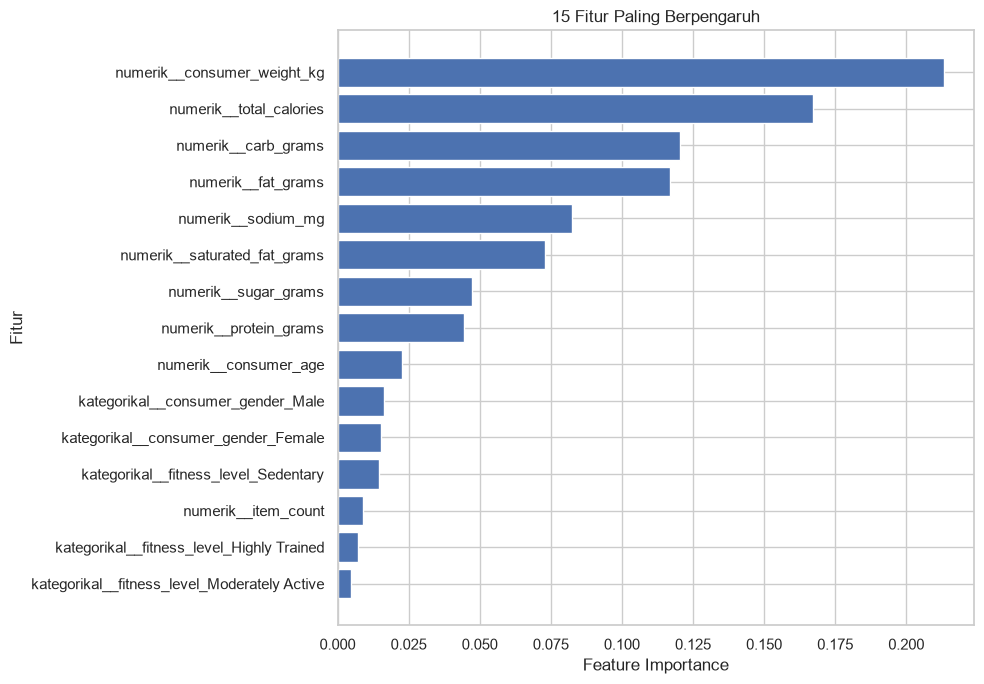

In [12]:

# Mengambil hasil preprocessing dari model
preprocessor_terlatih = model.named_steps["preprocessor"]
random_forest = model.named_steps["classifier"]

# Mengambil nama fitur setelah One-Hot Encoding
nama_fitur = preprocessor_terlatih.get_feature_names_out()

# Mengambil nilai feature importance
importance = random_forest.feature_importances_

# Membuat tabel importance
tabel_importance = pd.DataFrame({
    "Fitur": nama_fitur,
    "Importance": importance
})

# Mengurutkan fitur dari nilai terbesar
tabel_importance = tabel_importance.sort_values(
    by="Importance",
    ascending=False
)

# Menampilkan 15 fitur teratas
display(tabel_importance.head(15))

# Membuat grafik feature importance
top_fitur = tabel_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_fitur["Fitur"], top_fitur["Importance"])
plt.title("15 Fitur Paling Berpengaruh")
plt.xlabel("Feature Importance")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()


## 13. Kesimpulan

Pada penelitian ini, algoritma Random Forest Classification
digunakan untuk memprediksi kategori workout_shock_tier
berdasarkan fitur makanan cepat saji dan karakteristik konsumen.

Kesimpulan akhir dibuat berdasarkan nilai accuracy,
precision, recall, F1-score, confusion matrix, serta fitur
yang memiliki importance tertinggi.

Nilai evaluasi dan fitur terpenting harus diisi berdasarkan
hasil aktual yang diperoleh setelah notebook dijalankan.
Hasil prediksi menunjukkan pola dalam dataset, bukan
penilaian medis mengenai kebutuhan olahraga seseorang.